# 02 Preparacion de los datos

Proyecto: detección de pagos y proveedores duplicados en el proceso de cuentas por pagar del Banco.

Este notebook corresponde al punto 8 del enunciado. Parte de la misma base de la entrega 1 y construye la tabla con la que entrenamos los modelos.

Qué cambió frente a la entrega 1. En la entrega 1 el puntaje de riesgo lo íbamos a construir con reglas, y la etiqueta dependia de que el Banco revisara una muestra. Los comentarios señalaron que de esta forma la solucion se quedaba en lo descriptivo. Es por esto, que en la entrega final planteamos el problema como clasificación supervisada, con una etiqueta que ya existe en los datos:

- Unidad de analisis: el par de facturas consecutivas del mismo proveedor, con la misma moneda y el mismo monto, creadas a 90 días o menos una de la otra.
- Clase positiva (y = 1): una de las dos facturas terminó anulada, disputada o rechazada. Es decir, el Banco ya trato ese par como un cobro repetido que no se podía pagar dos veces.
- Clase negativa (y = 0): las dos facturas se aprobaron.

Con esto, el modelo apprende cómo se ve un par que el Banco ya detecto como repetido. Después, lo aplicamos a los pares en los que las dos facturas se aprobaron. Los de puntaje alto se pareccen a los duplicados que el Banco detecto, pero se pagaron, así que forman la cola de revisión. Además, algunos pares con y = 0 pueden ser dupicados que naide dtectó, por lo tanto la precisión quese mide con esta etiqueta es conservadora. La precision real se mide con la revisión del Banco en el notebook 03.


## 1. Configuración

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from Levenshtein import ratio as lev_ratio

pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE=42
RAW_PATH = "../data/raw/Spend_FA_x_Transit_x_User_ID.xlsx"
PARES_PATH = "../data/processed/pares.parquet"
REGLA_PATH = "../data/processed/cola_regla_numero.parquet"
MONTO = "Invoice total with tax (CAD)"
MONTO_ORIG = "Invoice Total with Tax Amount"  # los pares se arman con el monto original, no con el convertido a CAD
VENTANA_INI,VENTANA_FIN="2024-09-01","2026-06-01"  # desde sep-2024 por el cambio de proceso de ago-2024 (ver notebook 01)
ESTADOS_FRICCION = ["voided", "disputed", "rejected"]
DIAS_MAX = 90  # 90 días alcanza para cuotas menusales y trimestrales

## 2. Carga y seudonimizacion

Usamos las mismas reglas de la entrega 1. Primero, leemos las columnas de códigos como texto y la llave del proveedor es la entidad junto con el código. Después, cambiamos los nombres de proveedores y personas por seudónimos (PROV_xxxx) antes de cualquier salida. El número de factura real lo usamos solo en memoria para medir la similitud entre los dos numeros del par, y nunca lo imprimimos ni lo guardamos.

In [2]:
columnas_texto = ["Invoice Number", "Contract Number", "Account Segment 1", "Account Segment 2",
                "Account Segment 3", "Account Segment 4"]
raw_df = pd.read_excel(RAW_PATH,dtype={c: str for c in columnas_texto})

def separar_proveedor(nombre):
    if pd.isna(nombre):
        return (np.nan, np.nan, np.nan)
    m=re.match(r"^(.*)_(\d+)_(\d+)$",nombre) or re.match(r"^.*\((.*)_(\d+)_(\d+)\)$",nombre)
    return (m.group(1).strip(), m.group(2), m.group(3)) if m else (nombre.strip(), np.nan, np.nan)

df = raw_df.copy()
df[["prov_nombre_base", "prov_entidad", "prov_codigo"]] = pd.DataFrame(
   df["Invoice Supplier Name"].apply(separar_proveedor).tolist(), index=df.index)
df["prov_llave"] = df["prov_entidad"]+"_"+df["prov_codigo"]
# mismo orden de la entrega 1 para que los PROV_xxxx coincidan
llaves=sorted(df["prov_llave"].dropna().unique())
mapa_proveedores={k: f"PROV_{i:04d}" for i,k in enumerate(llaves,start=1)}
df["proveedor_id"]=df["prov_llave"].map(mapa_proveedores)

# una versión para la similitud y otra sin signos ni ceros, que es lo que SmartBuy no compara
df["num_mayus"]=df["Invoice Number"].str.upper().str.strip()
df["num_norm"] = df["num_mayus"].str.replace(r"[^A-Z0-9]", "", regex=True).str.lstrip("0")

df = df.drop(columns=["Invoice Supplier Name","prov_nombre_base","prov_llave","Invoice Number","User Login",
                      "User ID", "Original Approver ID", "Requested by Name", "Finance Approver",
                    "Finance Approver2", "Original Approver Name"])
del raw_df
print("Facturas:",f"{len(df):,}","| columnas:",df.shape[1],"| proveedores:",df["proveedor_id"].nunique())

Facturas: 75,631 | columnas: 23 | proveedores: 3354


### Distribución del monto y concentración del gasto

Estas dos graficas responden al comentario de la entrega 1, que pidio mostrar la distribución de los montos y la concentración de los proveedores. Para esto, usamos las facturas aprobadas de la ventana analítica.

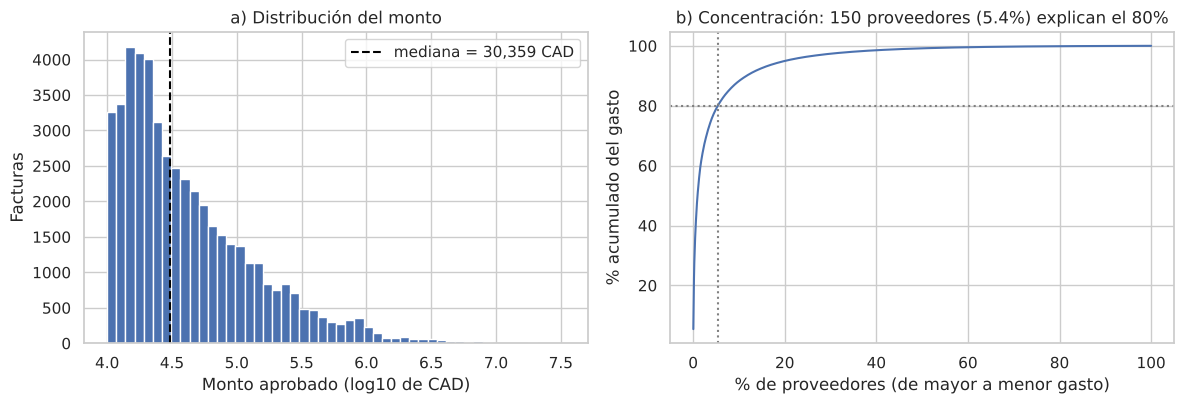

Facturas aprobadas: 48,457 | proveedores: 2,775 | 10 más grandes: 33.0% del gasto


In [3]:
aprob = df[(df["Invoice Created Date"] >= VENTANA_INI) & (df["Invoice Created Date"] < VENTANA_FIN)
        & (df["Invoice Status"]=="approved") & df["proveedor_id"].notna()]
gasto_prov = aprob.groupby("proveedor_id")[MONTO].sum().sort_values(ascending=False)
acumulado = gasto_prov.cumsum() / gasto_prov.sum() * 100
n_80 = int((acumulado < 80).sum()) + 1

fig,axes=plt.subplots(1,2,figsize=(12,4.2))
axes[0].hist(np.log10(aprob[MONTO].dropna()),bins=50,color="#4C72B0",edgecolor="white")
axes[0].axvline(np.log10(aprob[MONTO].median()), color="black", linestyle="--",
                  label=f"mediana = {aprob[MONTO].median():,.0f} CAD")
axes[0].set_xlabel("Monto aprobado (log10 de CAD)")
axes[0].set_ylabel("Facturas")
axes[0].set_title("a) Distribución del monto")
axes[0].legend()
axes[1].plot(np.arange(1,len(acumulado) + 1) / len(acumulado) * 100,acumulado.values,color="#4C72B0")
axes[1].axhline(80, color="gray", linestyle=":")
axes[1].axvline(n_80 / len(acumulado) * 100,color="gray",linestyle=":")
axes[1].set_xlabel("% de proveedores (de mayor a menor gasto)")
axes[1].set_ylabel("% acumulado del gasto")
axes[1].set_title(f"b) Concentración: {n_80} proveedores ({n_80 / len(acumulado):.1%}) explican el 80%")
plt.tight_layout()
plt.show()
print(f"Facturas aprobadas: {len(aprob):,} | proveedores: {len(gasto_prov):,} | "
        f"10 más grandes: {acumulado.iloc[9]:.1f}% del gasto")

## 3. Historia del proveedor

Antes de recortar la ventana, contamos cuántas facturas había creado cada proveedor hasta el momento de cada factura. Usamos toda la historia desde junio de 2022, dado que un proveedor con mucha historia y cobros recurrentes se comporta distinto a uno ocasional. Además, solo contamos facturas anteriores, así que la variable está diisponible en el momento de crear la factura.

In [4]:
df=df.sort_values(["Invoice Created Date"]).reset_index(drop=True)
df["fid"] = np.arange(len(df))
# con todas las facturas, no solo la ventana, para no subestimar la historia
df["n_facturas_previas_prov"] = df.groupby("proveedor_id").cumcount()
df.loc[df["proveedor_id"].isna(),"n_facturas_previas_prov"] = np.nan

## 4. Construcción de los pares

Cómo llegamos a la ventana (septiembre 2024 a mayo 2026). Al principio la idea era usar todo el periodo, de junio de 2022 a julio de 2026, para tener más pares. Sin embargo, en el notebook 01 vimos que eso mezclaba dos procesos distintos. En agosto de 2024 el volumen se triplico, apareció la carga por sftp y las facturas con contrato pasaron de entre 65% y 82% a cerca de 25% (V de Cramér de 0,36 para el canal y 0,39 para el contrato). Un modelo entrenado con los dos periodos aprendería patrones de un proceso que ya no existe, por eso la ventana arranca en septiembre de 2024. En cambio, el final lo definió la temporalidad: las facturas de junio y julio de 2026 todavía estaban abiertas y sin estado final, así que la ventana cierra el 31 de mayo de 2026. En la retroalimentacion el Banco no explicó la causa deese cambio, por lo tanto la decisión se basa en lo que muestran los datos.

Tomamos las facturas de la ventana analitica que ya tienen un resultado: aprobadas, anuladas, disputadas o rechazadas. Las que siguen en proceso (por ejemplo on_hold o pending_receipt) no tienen etiqutea y quedan por fuera. Luego, para cada factura buscamos la anterior del mismo proveedor con la misma moneda y el mismo monto en la moneda original. Si la distancia es de 90 días o menos, las dos forman un par.

In [5]:
ventana = df[(df["Invoice Created Date"] >= VENTANA_INI) & (df["Invoice Created Date"] < VENTANA_FIN)
               & df["proveedor_id"].notna() & df["Invoice Status"].isin(["approved"]+ESTADOS_FRICCION)].copy()
print("Facturas resueltas en la ventana con proveedor:", f"{len(ventana):,}")
ventana = ventana.sort_values(["proveedor_id","Invoice Currency Code",MONTO_ORIG,"Invoice Created Date","fid"])
# solo con la anterior: con todas, una cuota mensual daría muchísimos pares repetidos
grupo = ventana.groupby(["proveedor_id", "Invoice Currency Code", MONTO_ORIG])
cols_par = ["fid", "Invoice Created Date", "Invoice Status", "num_mayus", "num_norm", "Invoice Channel", "Creation Method"]
for c in cols_par:
    ventana["ant_" + c] = grupo[c].shift()

pares=ventana[ventana["ant_fid"].notna()].copy()
pares["dias_entre_facturas"] = (pares["Invoice Created Date"] - pares["ant_Invoice Created Date"]).dt.days
print("Pares consecutivos con el mismo proveedor, moneda y monto:", f"{len(pares):,}")
pares = pares[pares["dias_entre_facturas"] <= DIAS_MAX].copy()
print(f"Pares a {DIAS_MAX} días o menos:", f"{len(pares):,}")

Facturas resueltas en la ventana con proveedor: 51,154
Pares consecutivos con el mismo proveedor, moneda y monto: 13,851
Pares a 90 días o menos: 11,455


## 5. Variable objetivo

y = 1 cuando una de las dos facturas del par terminó con fricción (anulada, disputada o rechazada).

Cómo llegamos a esta etiqueta. El Banco no marca cuales pagos fueron duplicados, así que no había una variable objetivo lista. Por eso, probamos tres opciones:

1. En la entrega 1 usamos como objetivo provisional el "candidato a dupliacdo" (mismo proveedor y monto a 7 días o menos, o numero casi idéntico). No sirvió como etiqueta porque es la misma regla que queriamos superar, y un modelo entrenado con ella solo aprenderia a copiarla.
2. Después, probamos la fricción a nivel de factura. Tampoco funciono, dado que muchas anulaciones son correcciones normales (notebook 01, sección 3.5) y los campos que mejor la "predicen" son los de aprobación, que teinen fuga.
3. Al final pasamos al par. Una anulacion dentro de un par con el mismo proveedor y monto sí parece un cobro repetido, y la tabla de abajo lo respalda: entre 1 y 7 días la tasa está entre 16% y 17%, y en las cuotas mensuales (22 a 40 días) baja a 5,5%.

En cuanto al Banco, en la entrega 1 le propusimos etiquetar una muestra de 202 casos, y para esta entrega le mandamos el Excel con 30 pares y 20 grupos para revisar. En noviembre de 2026 el Banco reisó los 30 pares (notebook 03, sección 11). Como resultado, los pares que marco el moddelo resultaron ser facturas distintas, y los que tenían el mismo numero de factura sí eran duplicados. Por lo tanto, la etiqueta arpoximada sigue sirviendo para entrenar, pero en la cola la regla del numero va primero.

Por qué 90 días. Probamos ventanas más cortas, pero la tasa vuelve a subir entre 41 y 90 días (10,4%), así que cortar en 40 dejaba por fuera pares con fricción. Además, más allá de 90 días los pares serian casi siempre cuotas trimestrales o anuales.

In [6]:
# etiqueta aproximada porque el Banco no marca los duplicados
pares["y"] = (pares["Invoice Status"].isin(ESTADOS_FRICCION)
                | pares["ant_Invoice Status"].isin(ESTADOS_FRICCION)).astype(int)
pares["ambas_aprobadas"] = ((pares["Invoice Status"] == "approved")
                           & (pares["ant_Invoice Status"] == "approved")).astype(int)
print(f"Positivos: {pares['y'].sum():,} ({pares['y'].mean():.2%}) | negativos: {(1 - pares['y']).sum():,}")
print(f"Pares con las dos facturas aprobadas (candidatos para la cola): {pares['ambas_aprobadas'].sum():,}")
pd.crosstab(pares["ant_Invoice Status"], pares["Invoice Status"], margins=True, margins_name="Total")

Positivos: 1,086 (9.48%) | negativos: 10,369
Pares con las dos facturas aprobadas (candidatos para la cola): 10,369


Invoice Status,approved,disputed,rejected,voided,Total
ant_Invoice Status,,,,,
approved,10369,22,7,336,10734
disputed,41,22,0,5,68
rejected,12,0,1,1,14
voided,456,4,1,178,639
Total,10878,48,9,520,11455


La etiqueta se comporta como esperabamos a partir del histograma de días de la entrega 1. Cuando las dos facturas llegan con pocos días de diferencia, la proporción de pares con friccion es casi el doble que en el tramo de 21 a 40 días, que es donde caen las cuotas mensuales legítimas.

,pares,positivos,tasa
dias_entre_facturas,,,
0,2052,202,0.098
1-3,735,127,0.173
4-7,674,111,0.165
8-14,706,100,0.142
15-21,783,80,0.102
22-40,4275,235,0.055
41-90,2230,231,0.104


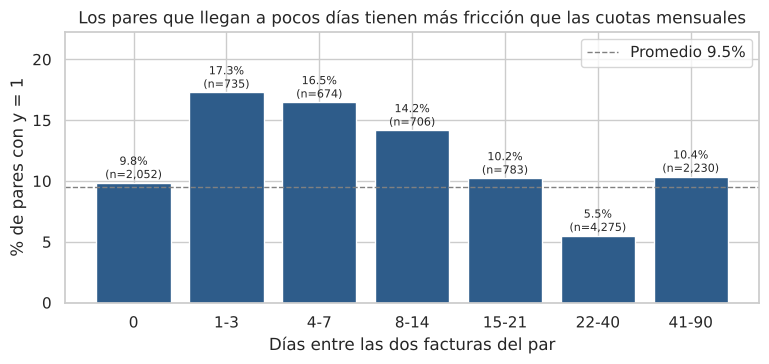

In [7]:
tramos=pd.cut(pares["dias_entre_facturas"], [-1, 0, 3, 7, 14, 21, 40, 90],
             labels=["0", "1-3", "4-7", "8-14", "15-21", "22-40", "41-90"])
tasa_tramo = pares.groupby(tramos, observed=True)["y"].agg(pares="size", positivos="sum", tasa="mean")
display(tasa_tramo)
fig,ax=plt.subplots(figsize=(8,3.8))
ax.bar(tasa_tramo.index.astype(str), tasa_tramo["tasa"] * 100, color="#2E5C8A")
ax.axhline(pares["y"].mean() * 100,color="grey",ls="--",lw=1,label=f"Promedio {pares['y'].mean():.1%}")
for i, (v, n) in enumerate(zip(tasa_tramo["tasa"], tasa_tramo["pares"])):
    ax.text(i, v * 100 + 0.4, f"{v:.1%}\n(n={n:,})", ha="center", fontsize=8)
ax.set_xlabel("Días entre las dos facturas del par"); ax.set_ylabel("% de pares con y = 1")
ax.set_title("Los pares que llegan a pocos días tienen más fricción que las cuotas mensuales")
ax.set_ylim(0, tasa_tramo["tasa"].max() * 100 + 5); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 6. Ingenieria de características

Todas las variables se pueden calcular en el momento en que llega la segunda factura del par. Es decir, ninguna depende del estado final ni de campos que se llenan durante la aprobacion.

- dias_entre_facturas (cómo se calcula: días enre la creación de las dos facturas; por qué ayuda: un duplicado suele llegar a pocos días)
- similitud_numero (cómo se calcula: similitud de Levenshtein entre los dos numeros de factura, de 0 a 1; por qué ayuda: un reenvío trae el mismo numero o uno casi igual)
- mismo_numero_normalizado (cómo se calcula: 1 si los números coinciden sin signos ni ceros a la izquierda; por qué ayuda: captura "INV-001" frente a "INV001")
- distancia_periodo (cómo se calcula: días que separan el par del periodo más cercano entre 30, 91 o 365 días; por qué ayuda: las cuotas mensuales, trimestrales y anuales son legítimas)
- mismo_canal, mismo_metodo (cómo se calcula: 1 si las dos facturas llegaron por el mismo canal y con el mismo método de creacion; por qué ayuda: un reenvio por otro canal es una señal de duplicado)
- canal (cómo se calcula: canal de la segunda factura, que puede ser csp, sftp, ui, email u otro; por qué ayuda: el riesgo cambia según el canal, hipótesis 2)
- moneda (cómo se calcula: CAD, USD u otra; por qué ayuda: controla la mezcla de monedas que la entrega 1 encontró relevante)
- log_monto (cómo se calcula: logaritmo en base 10 del monto en CAD; por qué ayuda: el monto es muy asimetrico, hipótesis 4)
- log_historia_proveedor (cómo se calcula: logaritmo de 1 más las facturas previas del proveedor; por qué ayuda: separa proveedores nuevos de recurrentes, hipótesis 3)

In [8]:
pares["similitud_numero"] = [lev_ratio(a, b) if isinstance(a, str) and isinstance(b, str) else np.nan
                               for a,b in zip(pares["num_mayus"],pares["ant_num_mayus"])]
pares["mismo_numero_normalizado"] = ((pares["num_norm"] == pares["ant_num_norm"])
                                   & pares["num_norm"].notna()).astype(int)
# las cuotas legítimas caen cerca de 30, 91 o 365 días
pares["distancia_periodo"] = np.minimum.reduce([(pares["dias_entre_facturas"] - p).abs() for p in (30, 91, 365)])
pares["mismo_canal"] = (pares["Invoice Channel"] == pares["ant_Invoice Channel"]).astype(int)
pares["mismo_metodo"] = (pares["Creation Method"] == pares["ant_Creation Method"]).astype(int)
pares["canal"]=pares["Invoice Channel"].where(pares["Invoice Channel"].isin(["csp", "sftp", "ui", "email"]), "otro")
pares["moneda"] = pares["Invoice Currency Code"].where(pares["Invoice Currency Code"].isin(["CAD", "USD"]), "otra")
pares["log_monto"] = np.log10(pares[MONTO])
pares["log_historia_proveedor"]=np.log1p(pares["n_facturas_previas_prov"])
VARS_NUM = ["dias_entre_facturas", "similitud_numero", "mismo_numero_normalizado", "distancia_periodo",
         "mismo_canal", "mismo_metodo", "log_monto", "log_historia_proveedor"]
VARS_CAT = ["canal", "moneda"]
pares[VARS_NUM].describe().T

,count,mean,std,min,25%,50%,75%,max
dias_entre_facturas,"11,455.000",25.868,22.810,0.000,4.000,26.000,35.000,90.000
similitud_numero,"11,428.000",0.735,0.153,0.000,0.667,0.769,0.833,0.977
mismo_numero_normalizado,"11,455.000",0.003,0.052,0.000,0.000,0.000,0.000,1.000
distancia_periodo,"11,455.000",15.497,11.193,0.000,4.000,15.000,28.000,30.000
mismo_canal,"11,455.000",0.972,0.164,0.000,1.000,1.000,1.000,1.000
mismo_metodo,"11,455.000",0.950,0.217,0.000,1.000,1.000,1.000,1.000
log_monto,"11,455.000",4.489,0.444,4.000,4.190,4.314,4.668,7.328
log_historia_proveedor,"11,455.000",5.692,2.133,0.693,4.078,5.905,7.588,8.770


## 7. Auditoría de fuga de informacion

En la entrega 1 encontramos que los campos de aprobación solo se llenan cuando la factura se aprueba. Al revisar el resto de columnas aparecen más casos. Por ejemplo, Account Segment 1 y 3 casi nunca están vacíos en las aprobadas, pero sí en una de cada cinco anuladas, porque la codificacion contable se completa durante la aprobación. Lo mismo pasa con Commodity, Account Segment 4, el contrato y el tipo de creador. Si estas columnas, o una bandera de "está vacío", entraran al modelo, este aprendería el resultado del proceso y no el riesgo de la factura. Es por esto, que decidimos excluirlas todas.

In [9]:
cols_revisar = ["Contract Number", "Commodity Level 1", "Account Segment 1", "Account Segment 3", "Account Segment 4",
                 "Invoice Created by Type", "Number of Approvers"]
nulos_estado = (ventana.groupby("Invoice Status")[cols_revisar].apply(lambda g: g.isna().mean() * 100).T.round(1))
nulos_estado["diferencia máx. (pp)"] = (nulos_estado.max(axis=1) - nulos_estado.min(axis=1)).round(1)
nulos_estado["decisión"] = np.where(nulos_estado["diferencia máx. (pp)"] > 5, "se excluye (fuga)", "no se usa (sin aporte)")
nulos_estado

Invoice Status,approved,disputed,rejected,voided,diferencia máx. (pp),decisión
Contract Number,74.100,34.100,93.500,73.100,59.400,se excluye (fuga)
Commodity Level 1,29.400,17.300,61.100,39.600,43.800,se excluye (fuga)
Account Segment 1,0.000,9.200,1.900,17.800,17.800,se excluye (fuga)
Account Segment 3,0.000,13.000,48.100,24.000,48.100,se excluye (fuga)
Account Segment 4,43.400,33.500,56.500,63.500,30.000,se excluye (fuga)
Invoice Created by Type,25.900,2.700,6.500,15.300,23.200,se excluye (fuga)
Number of Approvers,50.500,90.800,77.800,99.000,48.500,se excluye (fuga)


En cambio, las variables del modelo no tienen esta dependencia. La única con valores faltantes es la similitud del número, cuando una factura no trae número, y la imputamos en el notebook 03 con la mediana del conjunto de entrenamiento.

In [10]:
print("Faltantes por variable del modelo:")
print(pares[VARS_NUM + VARS_CAT].isna().sum().to_string())

Faltantes por variable del modelo:
dias_entre_facturas          0
similitud_numero            27
mismo_numero_normalizado     0
distancia_periodo            0
mismo_canal                  0
mismo_metodo                 0
log_monto                    0
log_historia_proveedor       0
canal                        0
moneda                       0


## 8. Comparación de las variables por clase

Antes de modelar revisamos si las variables separan las clases. Ninguna lo hace sola, lo cuál justifica un modelo que las combine. Las diferencias más claras están en tres variables. Primero, el cambio de canal o de método, ya que el 10% de los pares positivos cambia de canal frente al 2% de los negativos. Segundo, la historia del proveedor, porque los positivos vienen de proveedores con menos facturas previas. Tercero, el numero normalizado idéntico, que casi solo aparece en los positivos. Por otro lado, la similitud promedio del numero es parecida en las dos clases. Dado que, mucos proveedores numeran sus facturas en secuencia y dos números consecutivos ya se parecen mcho.

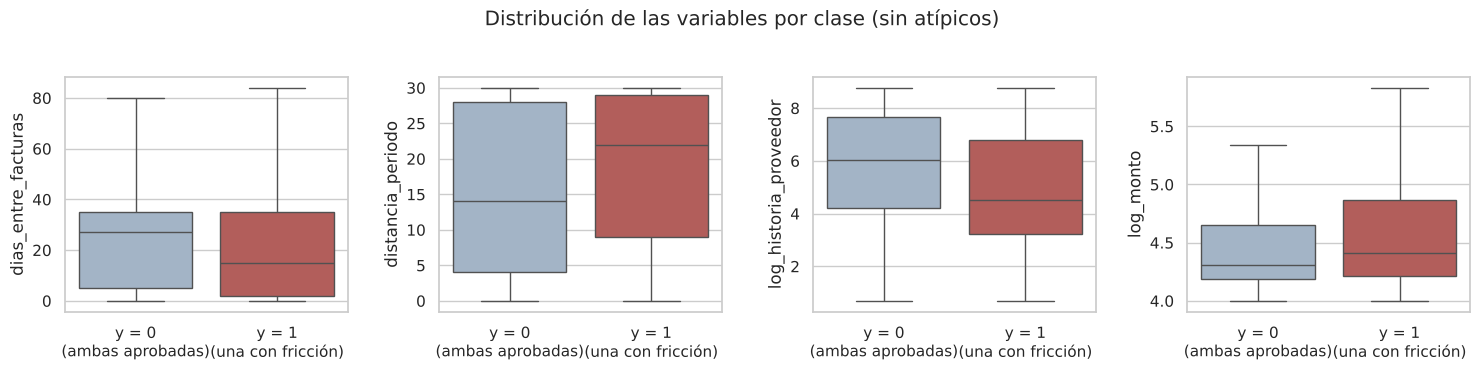

y                             0      1
dias_entre_facturas      26.220 22.506
similitud_numero          0.736  0.721
mismo_numero_normalizado  0.000  0.029
distancia_periodo        15.131 18.992
mismo_canal               0.980  0.901
mismo_metodo              0.963  0.825
log_monto                 4.477  4.598
log_historia_proveedor    5.782  4.833


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, v in zip(axes, ["dias_entre_facturas", "distancia_periodo", "log_historia_proveedor", "log_monto"]):
    sns.boxplot(data=pares, x="y", y=v, ax=ax, hue="y", palette=["#9DB4CC", "#C0504D"], legend=False, showfliers=False)
    ax.set_xticks([0,1],["y = 0\n(ambas aprobadas)","y = 1\n(una con fricción)"]); ax.set_xlabel("")
plt.suptitle("Distribución de las variables por clase (sin atípicos)", y=1.03)
plt.tight_layout(); plt.show()
print(pares.groupby("y")[VARS_NUM].mean().T.round(3))

## 9. Codificación one-hot

Las dos variables categoricas las codificamos con one-hot y drop_first=True, para dejar una categoría de referencia (canal csp y moneda CAD). En cambio, la imputación de la similitud del número y la estandarización de las variables continuas las hacemos en el notebook 03, despues de dividir los datos y con valores calculados solo en el conjunto de entrenamiento.

In [12]:
pares["tipo_canal"],pares["tipo_moneda"] = pares["canal"],pares["moneda"]  # el pipeline del 05 recibe el canal en texto y hace su propio one-hot
pares = pd.get_dummies(pares,columns=VARS_CAT,drop_first=True,dtype=int)
VARS_DUMMY=[c for c in pares.columns if c.startswith("canal_") or c.startswith("moneda_")]
print("Columnas creadas:",VARS_DUMMY)

Columnas creadas: ['canal_email', 'canal_otro', 'canal_sftp', 'canal_ui', 'moneda_USD', 'moneda_otra']


## 10. Diagrama de bloques de la preparación

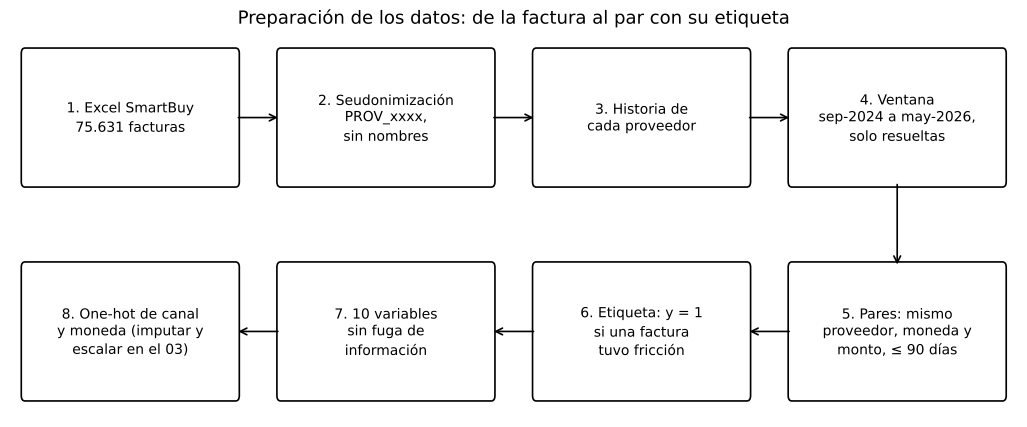

In [13]:
pasos = ["1. Excel SmartBuy\n75.631 facturas", "2. Seudonimización\nPROV_xxxx,\nsin nombres",
         "3. Historia de\ncada proveedor", "4. Ventana\nsep-2024 a may-2026,\nsolo resueltas",
         f"5. Pares: mismo\nproveedor, moneda y\nmonto, ≤ {DIAS_MAX} días", "6. Etiqueta: y = 1\nsi una factura\ntuvo fricción",
         "7. 10 variables\nsin fuga de\ninformación", "8. One-hot de canal\ny moneda (imputar y\nescalar en el 03)"]
# dos filas de 4 para que el texto quepa en cada caja
fig, ax = plt.subplots(figsize=(13, 5)); ax.axis("off")
ancho, alto, sep_x, sep_y = 2.8, 1.2, 0.6, 0.8
pos = [(i * (ancho + sep_x), alto + sep_y) for i in range(4)] + [((3 - i) * (ancho + sep_x), 0) for i in range(4)]
for i, (t, (x, y)) in enumerate(zip(pasos, pos)):
    ax.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.05", fc="white", ec="black", lw=1.2))
    ax.text(x + ancho / 2, y + alto / 2, t, ha="center", va="center", fontsize=10, color="black", linespacing=1.3)
for i in range(len(pos) - 1):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    if y1 == y2:
        ini = (x1 + ancho, y1 + alto / 2) if x2 > x1 else (x1, y1 + alto / 2)
        fin = (x2, y2 + alto / 2) if x2 > x1 else (x2 + ancho, y2 + alto / 2)
    else:
        ini, fin = (x1 + ancho / 2, y1), (x2 + ancho / 2, y2 + alto)
    ax.annotate("", xy=fin, xytext=ini, arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
ax.set_xlim(-0.2, 4 * ancho + 3 * sep_x + 0.2); ax.set_ylim(-0.2, 2 * alto + sep_y + 0.2)
ax.set_title("Preparación de los datos: de la factura al par con su etiqueta", fontsize=13, color="black")
plt.show()

## 11. Exportar la tabla de pares

La tabla la guardamos en data/processed/, que no se sube al repositorio. Además, no tiene numeros de factura ni nombres, solo el seudónimo del proveedor, los identificadores internos de las facturas, las fechas, el monto, las variables y la etiqueta.

In [14]:
cols_salida = (["fid","ant_fid","proveedor_id","Invoice Created Date","ant_Invoice Created Date","Invoice Status",
                 "ant_Invoice Status", MONTO, "ambas_aprobadas", "y"] + VARS_NUM + VARS_DUMMY + ["tipo_canal", "tipo_moneda"])
salida=pares[cols_salida].rename(columns={"Invoice Created Date": "fecha", "ant_Invoice Created Date": "fecha_anterior",
                                            "Invoice Status": "estado","ant_Invoice Status": "estado_anterior",
                                              MONTO: "monto_cad"})
salida["ant_fid"] = salida["ant_fid"].astype(int)
salida.sort_values("fecha").to_parquet(PARES_PATH, index=False)
print("Archivo:",PARES_PATH,"| pares:",f"{len(salida):,}","| columnas:",salida.shape[1])

Archivo: ../data/processed/pares.parquet | pares: 11,455 | columnas: 26


## 11.1 Pares de la regla del número en todo el histórico

Este paso lo agregamos despues de la revisión del Banco (notebook 03, sección 11). El Banco confirmó que los pares donde el numero de factura es igual al quitar signos y ceros, o donde uno es el otro con un sufijo, sí son facturas duplicadas. Además, los cuatro pagos dobles estaban por fuera de la ventana. Por eso, aquí buscamos esos pares entodo el historico (junio de 2022 a julio de 2026) y sin límite de días, entre facturas aprobadas del mismo proveedor, moneda y monto. Estos pares son el primer nivel de la cola y los guardamos sin números de factura.

In [15]:
def mismo_numero_base(a, b):
    # mismo criterio q la API
    if not a or not b:
        return False
    return a == b or (min(len(a), len(b)) >= 6 and (a.startswith(b) or b.startswith(a)))

aprob_hist = df[(df["Invoice Status"] == "approved") & df["proveedor_id"].notna() & df["num_norm"].notna()]
filas=[]
for (prov, mon, monto), g in aprob_hist.groupby(["proveedor_id", "Invoice Currency Code", MONTO_ORIG]):
    if len(g)<2 :
        continue
    regs= g.sort_values("Invoice Created Date")[["fid", "Invoice Created Date", "num_norm", MONTO]].to_numpy()
    for i in range(len(regs)):
        for j in range(i+1,len(regs)):
            if mismo_numero_base(regs[i][2], regs[j][2]):
                filas.append({"proveedor_id": prov, "ant_fid": regs[i][0], "fid": regs[j][0], "fecha_anterior": regs[i][1],
                              "fecha": regs[j][1], "dias": (regs[j][1] - regs[i][1]).days, "monto_cad": regs[j][3],
                              "exacto": int(regs[i][2] == regs[j][2])})
cola_regla=pd.DataFrame(filas)
en_ventana = cola_regla["fecha"].between(VENTANA_INI, VENTANA_FIN) & (cola_regla["dias"] <= DIAS_MAX)
print(f"Pares de la regla del número: {len(cola_regla)} | proveedores: {cola_regla['proveedor_id'].nunique()} | "
      f"monto de la factura repetida: {cola_regla['monto_cad'].sum():,.0f} CAD")
print(f"Número igual exacto: {cola_regla['exacto'].sum()} | con sufijo: {(cola_regla['exacto'] == 0).sum()} | "
      f"dentro de la ventana y a 90 días o menos: {en_ventana.sum()}")
print(cola_regla.groupby(cola_regla["fecha"].dt.year).agg(pares=("fid", "size"), monto_cad=("monto_cad", "sum")).round(0).to_string())
cola_regla.to_parquet(REGLA_PATH, index=False)

Pares de la regla del número: 66 | proveedores: 29 | monto de la factura repetida: 8,992,535 CAD
Número igual exacto: 6 | con sufijo: 60 | dentro de la ventana y a 90 días o menos: 17
       pares     monto_cad
fecha                     
2022       3    78,362.000
2023      27 1,034,962.000
2024      16 1,638,701.000
2025      12 6,066,948.000
2026       8   173,561.000


La regla del número marca pocos pares en cuatro años, pero son los que el Banco confirmó como duplicados. La mayoría (49 de 66) quedan por fuera de la ventana o a más de 90 días, y por eso el modelo no los veía. Como resultado, esta lista es la que el analista revisa primero y después sigue la cola del modelo.

## 12. Resumen

- La tabla final tiene un par por fila, una etiqueta que viene del propio proceso del Banco y 10 variables (ocho numéricas y dos categoricas) que existen en el momento de crear la factura.
- La clase positiva es cerca del 9,5% de los pares, es decir, un desbalance moderado. Lo tratamos con pesos por clase (class_weight) en el notebook 03, y estratificamos la division para conservar esa proporción.
- Por fuga excluimos los campos de aprobación, los segmentos contables, Commodity, el contrato y el tipo de creador. Además, eliminamos los nombres de personas por privacidad.
- Los datos alcanzan para entrenar el modelo, pero la etiqueta aproximada no equivale a un pago doble. La revisión del Banco mostró que la señal más fuerte es el número de factura, por lo tanto agregamos la lista de la regla del número sobre todo el histórico (sección 11.1).